# TA LAB: does Retail-Plus's reorders-per-member reward reorders or orders?

**Week 4, Monday, the TA-led practice lab.** The head of Retail-Plus wants a growth
number: reorders placed per member. The app's auto-reorder window ran from 10 to 30
September 2026; the comparison window is 20 August to 9 September 2026. Both windows sit
after the monsoon sale's last day (19 August). Compute reorders per member in each window,
booked revenue per member in each window, and the ratio of each. The lab's twelve rows and
the plant sit in the TA note; your job is to find them.

> *Illustrative case: Kalpa Retail is the programme's fictional client.*

**Who needs the answer.** The head of Retail-Plus, who is about to pitch the number at the
growth review. **The questions on the way.**

1. How many reorders per Retail-Plus member sit in each window?
2. How does booked revenue per member compare across the two windows?
3. What are the auto-reorders doing to each number?

**Setup.** Load the Kalpa data from `../data/`. Nothing in this notebook names a plant
before the groupby finds it.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
members = pd.read_csv("../data/C2_W04_D01_kalpa_members_STUDENT.csv")
reorders = pd.read_csv("../data/C2_W04_D01_kalpa_app_reorders_STUDENT.csv")
reorders["placed_date"] = pd.to_datetime(reorders["placed_ts"]).dt.date
print(f"members: {len(members)}, reorders: {len(reorders)}")

members: 120, reorders: 948


## Where does the lab sit on the method's ladder?

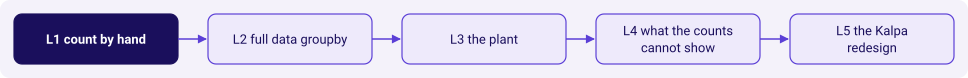

In [2]:
kit.flow(["L1 count by hand", "L2 full data groupby", "L3 the plant",
          "L4 what the counts cannot show", "L5 the Kalpa redesign"], lit=0)

## How many reorders per Retail-Plus member sit in each window?

**Predict first.** The strip's story said "reorders placed per member in the window over
the comparison prints 1.22". Which direction do you think the ratio goes?

- a) About 0.80 (window below comparison)
- b) About 1.00 (identical)
- c) About 1.20 (window above comparison)
- d) About 2.00 (double)

In [3]:
import datetime as dt
COMP = (dt.date(2026, 8, 20), dt.date(2026, 9, 9))
WIN = (dt.date(2026, 9, 10), dt.date(2026, 9, 30))

in_comp = reorders[reorders["placed_date"].between(*COMP)]
in_win = reorders[reorders["placed_date"].between(*WIN)]
comp_per_member = len(in_comp) / len(members)
win_per_member = len(in_win) / len(members)
ratio = win_per_member / comp_per_member
print(f"reorders per member, comparison: {comp_per_member:.2f}")
print(f"reorders per member, window: {win_per_member:.2f}")
print(f"ratio: {ratio:.2f}")

reorders per member, comparison: 3.56
reorders per member, window: 4.34
ratio: 1.22


**What happened.** The answer is c. Reorders per member rose by about 22 percent from the
comparison window to the auto-reorder window. The number the head of Retail-Plus wants to
pitch is up.

## How does the ratio read as a chart?

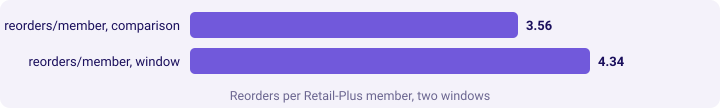

In [4]:
kit.bars([("reorders/member, comparison", round(comp_per_member, 2)),
          ("reorders/member, window", round(win_per_member, 2))],
         title="Reorders per Retail-Plus member, two windows")

## How does booked revenue per member compare across the two windows?

Booked revenue is the value of every reorder placed, whatever its status.

In [5]:
comp_value = in_comp["value_rs"].sum()
win_value = in_win["value_rs"].sum()
print(f"booked revenue per member, comparison: Rs {comp_value/len(members):,.0f}")
print(f"booked revenue per member, window: Rs {win_value/len(members):,.0f}")
print(f"ratio: {win_value / comp_value:.2f}")

booked revenue per member, comparison: Rs 1,392
booked revenue per member, window: Rs 1,336
ratio: 0.96


**What happened.** Booked revenue per member fell to about 0.96 of the comparison. The
reorders are more frequent and smaller. The number that rose and the number that fell say
different things about the same window.

## What are the auto-reorders doing to each number? (your-turn cell)

**Predict first.** Of the reorders in the auto-reorder window, how many were delivered as
separate orders (status "delivered")? The next cell is empty. **Your task:** group the
window's reorders by `status` and `auto`, and read what you find.

**What the room finds.** The window's reorders are nearly all `auto == True`, and no
reorder is delivered. The statuses are `cancelled`, `merged` or `pending`. The reorders
count toward "reorders placed per member" but not toward "orders delivered". The growth
number the head of Retail-Plus wants to pitch rises on auto-reorders that never earn
revenue. The analysis below shows it.

In [6]:
print(in_win.groupby(["auto", "status"]).size().unstack(fill_value=0))
delivered_window = in_win[in_win["status"] == "delivered"]
print(f"delivered reorders in window: {len(delivered_window)}")

status  cancelled  merged  pending
auto                              
True          162     176      183
delivered reorders in window: 0


**What happened.** Every reorder in the window is auto and none is delivered. The 22
percent rise is paid for by auto-reorders that are cancelled by the member or merged into
the next manual order. The growth number is a Wells-Fargo-style measurement: counted
toward the goal, with no condition that any revenue follows.

## What is the Kalpa fix, written to the same template as Uber's?

The growth plan's north star for Kalpa Retail is delivered orders per active customer per
month. The three guardrails are revenue per active customer, discount share of booked
revenue, and the return rate. The two leading inputs are add-to-cart events per active app
member and new Retail-Plus sign-ups. Each learner writes this definition in their own
words in the unguided exercise.

In [7]:
kalpa_def = pd.DataFrame({
    "line": ["numerator", "denominator", "window", "exclusions",
             "what it does not reward", "guardrails", "leading inputs"],
    "value": ["delivered orders",
               "customers active in the month",
               "the calendar month",
               "cancelled orders, returns within window, test accounts",
               "reorders placed, auto-reorders not delivered, add-to-cart counts",
               "revenue per active customer, discount share of booked, return rate",
               "add-to-cart events, new Retail-Plus sign-ups"]
})
kalpa_def

,line,value
0,numerator,delivered orders
1,denominator,customers active in the month
2,window,the calendar month
3,exclusions,"cancelled orders, returns within window, test ..."
4,what it does not reward,"reorders placed, auto-reorders not delivered, ..."
5,guardrails,"revenue per active customer, discount share of..."
6,leading inputs,"add-to-cart events, new Retail-Plus sign-ups"


## What picture closes the lab?

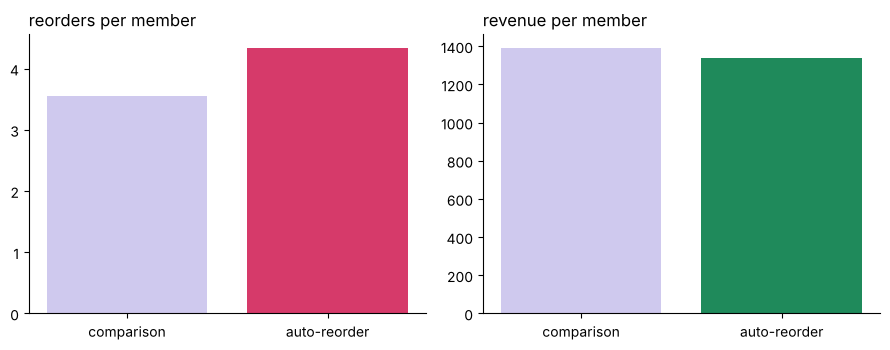

In [8]:
import matplotlib.pyplot as plt
reorders_series = pd.DataFrame({
    "window": ["comparison", "auto-reorder"],
    "reorders_per_member": [comp_per_member, win_per_member],
    "revenue_per_member": [comp_value / len(members),
                            win_value / len(members)],
})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.0, 3.6))
ax1.bar(reorders_series["window"],
        reorders_series["reorders_per_member"],
        color=["#CFC9EE", "#D63A6A"])
ax1.set_title("reorders per member", loc="left")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax2.bar(reorders_series["window"],
        reorders_series["revenue_per_member"],
        color=["#CFC9EE", "#1F8A5B"])
ax2.set_title("revenue per member", loc="left")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## What does the lab close with?

In [9]:
kit.check("reorders per member ratio about 1.22", round(ratio, 2) == 1.22)
kit.check("booked revenue per member ratio about 0.96",
          round(win_value / comp_value, 2) == 0.96)
kit.check("no delivered reorder in the auto-reorder window",
          len(in_win[in_win["status"] == "delivered"]) == 0)
kit.check("every auto reorder status is cancelled, merged or pending",
          set(in_win["status"].unique()).issubset({"cancelled", "merged", "pending"}))
kit.check("Kalpa definition has seven lines", len(kalpa_def) == 7)

**Lab close.** The method travels. The head of Retail-Plus's "reorders placed per member"
is to Kalpa what "peak online hours" is to Uber: a number that rose on a measurement with
no condition that the thing it stands for (a delivered order) followed. The redesign writes
the seven lines, and the growth review hears the honest number.

> **Kavya's review.** "You found the plant by refusing to call a reorder an order. The
> weekly growth review is this week."